# Calorie model – Sprint 1 starter
Covers: (1) load and inspect the data, (2) MET-formula baseline, (3) Linear Regression and Random Forest.
Edit the paths in the next cell, then run top to bottom. Write your own observations in the *Notes* cells – those become your report.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# ---- CONFIG: point these at your downloaded Kaggle files ----
# Some versions of the dataset ship as two files (exercise.csv + calories.csv, joined on User_ID),
# others as one file. If you have ONE file, set EXERCISE_CSV = None.
from pathlib import Path
# Works whether the kernel starts in notebooks/ or in the project root
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").is_dir())
RAW = ROOT / "data" / "raw" / "fmendes-DAT263x-demos"
CALORIES_CSV = RAW / "calories.csv"
EXERCISE_CSV = RAW / "exercise.csv"
RANDOM_STATE = 42

## 1. Load and inspect

In [2]:
df = pd.read_csv(CALORIES_CSV)
if EXERCISE_CSV:
    df = pd.read_csv(EXERCISE_CSV).merge(df, on="User_ID", how="inner")
print(df.shape)
df.head()

(15000, 9)


,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
0,14733363,male,68,190.0,94.0,29.0,105.0,40.8,231.0
1,14861698,female,20,166.0,60.0,14.0,94.0,40.3,66.0
2,11179863,male,69,179.0,79.0,5.0,88.0,38.7,26.0
3,16180408,female,34,179.0,71.0,13.0,100.0,40.5,71.0
4,17771927,female,27,154.0,58.0,10.0,81.0,39.8,35.0


In [3]:
print(df.dtypes, "\n")
print("Missing values:\n", df.isna().sum(), "\n")
print("Duplicate rows:", df.duplicated().sum())
df.describe().T

User_ID         int64
Gender            str
Age             int64
Height        float64
Weight        float64
Duration      float64
Heart_Rate    float64
Body_Temp     float64
Calories      float64
dtype: object 

Missing values:
 User_ID       0
Gender        0
Age           0
Height        0
Weight        0
Duration      0
Heart_Rate    0
Body_Temp     0
Calories      0
dtype: int64 

Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
User_ID,15000.0,1.497736e+07,2.872851e+06,10001159.0,12474190.75,14997285.0,17449278.75,19999647.0
Age,15000.0,4.278980e+01,1.698026e+01,20.0,28.00,39.0,56.00,79.0
Height,15000.0,1.744651e+02,1.425811e+01,123.0,164.00,175.0,185.00,222.0
Weight,15000.0,7.496687e+01,1.503566e+01,36.0,63.00,74.0,87.00,132.0
Duration,15000.0,1.553060e+01,8.319203e+00,1.0,8.00,16.0,23.00,30.0
Heart_Rate,15000.0,9.551853e+01,9.583328e+00,67.0,88.00,96.0,103.00,128.0
Body_Temp,15000.0,4.002545e+01,7.792299e-01,37.1,39.60,40.2,40.60,41.5
Calories,15000.0,8.953953e+01,6.245698e+01,1.0,35.00,79.0,138.00,314.0


In [4]:
# Outlier check (IQR rule) – report, don't silently delete
num = df.select_dtypes("number").drop(columns=["User_ID"], errors="ignore")
q1, q3 = num.quantile(.25), num.quantile(.75); iqr = q3 - q1
outliers = ((num < q1 - 1.5*iqr) | (num > q3 + 1.5*iqr)).sum()
print("Rows outside 1.5*IQR per column:\n", outliers)
# Physically impossible values
bad = df[(df["Duration"] <= 0) | (df["Weight"] <= 0) | (df["Age"] <= 0)]
print("\nImpossible rows:", len(bad))

Rows outside 1.5*IQR per column:
 Age             0
Height         14
Weight          6
Duration        0
Heart_Rate      1
Body_Temp     369
Calories        4
dtype: int64

Impossible rows: 0


**Notes:** see `Sprint-Docs-Notes/Sprint 2 - Data notes.docx`, Section 1.

## 1b. Synthetic-data checks
Kaggle fitness datasets are often generated, not measured. Two quick checks show whether the numbers behave like real physiology:
1. **Calories vs. weight** – a heavier person burns more energy for the same activity and time (kcal = MET × kg × hours). Comparing *calories per hour* removes the effect of session length.
2. **Calories per hour by workout type** (Gym Members only) – yoga should burn far less per hour than HIIT or cardio.

Gym Members: (973, 16)


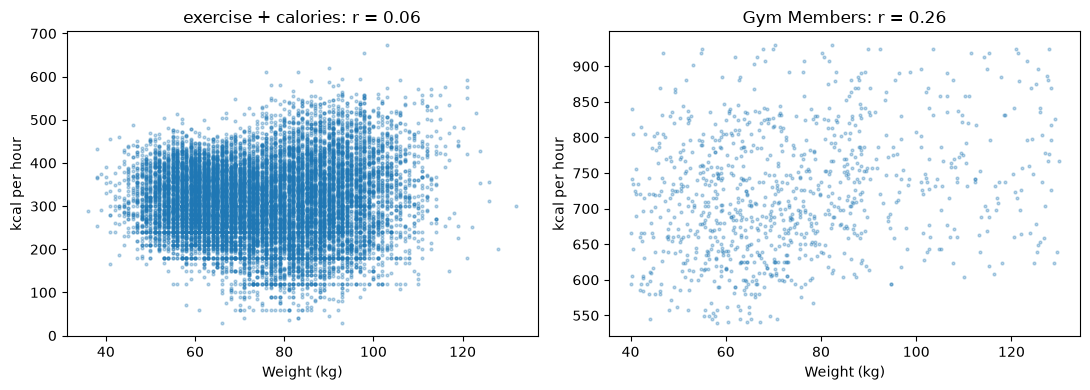

Correlation of total calories with weight:
  exercise + calories: 0.035
  Gym Members:         0.095


In [5]:
GYM_CSV = ROOT / "data" / "raw" / "Gym-Members-Exercise-Dataset" / "gym_members_exercise_tracking.csv"
gym = pd.read_csv(GYM_CSV)
gym["kcal_per_hour"] = gym["Calories_Burned"] / gym["Session_Duration (hours)"]
df["kcal_per_hour"] = df["Calories"] / (df["Duration"] / 60)   # Duration in minutes
print("Gym Members:", gym.shape)

# Check 1: calories vs weight
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
for ax, (name, data, w, k) in zip(axes, [("exercise + calories", df, "Weight", "kcal_per_hour"),
                                         ("Gym Members", gym, "Weight (kg)", "kcal_per_hour")]):
    ax.scatter(data[w], data[k], s=4, alpha=.3)
    ax.set_xlabel("Weight (kg)"); ax.set_ylabel("kcal per hour")
    ax.set_title(f"{name}: r = {data[w].corr(data[k]):.2f}")
plt.tight_layout(); plt.show()

print("Correlation of total calories with weight:")
print("  exercise + calories:", round(df["Calories"].corr(df["Weight"]), 3))
print("  Gym Members:        ", round(gym["Calories_Burned"].corr(gym["Weight (kg)"]), 3))

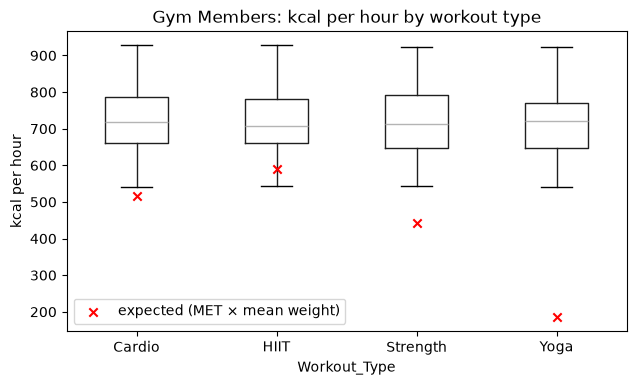

,mean,median,std,count,expected_kcal_per_hour
Workout_Type,,,,,
Yoga,717.0,720.0,86.0,239,185.0
Strength,724.0,714.0,94.0,258,443.0
Cardio,724.0,718.0,84.0,255,517.0
HIIT,717.0,708.0,83.0,221,591.0


In [6]:
# Check 2: calories per hour by workout type (Gym Members)
# Rough expectation for the average member: MET x mean weight. METs are approximate
# Compendium-style values – verify them against the Compendium of Physical Activities before citing.
MET_REF = {"Yoga": 2.5, "Strength": 6.0, "Cardio": 7.0, "HIIT": 8.0}
mean_w = gym["Weight (kg)"].mean()
by_type = gym.groupby("Workout_Type")["kcal_per_hour"].agg(["mean", "median", "std", "count"])
by_type["expected_kcal_per_hour"] = [MET_REF[t] * mean_w for t in by_type.index]
by_type = by_type.round(0).sort_values("expected_kcal_per_hour")

gym.boxplot(column="kcal_per_hour", by="Workout_Type", figsize=(7, 4), grid=False)
plt.scatter(range(1, len(by_type) + 1),
            [MET_REF[t] * mean_w for t in sorted(gym["Workout_Type"].unique())],
            color="red", marker="x", zorder=3, label="expected (MET × mean weight)")
plt.suptitle(""); plt.title("Gym Members: kcal per hour by workout type")
plt.ylabel("kcal per hour"); plt.legend(); plt.show()
by_type

**Notes:** see `Sprint-Docs-Notes/Sprint 2 - Data notes.docx`, Section 2.

## 1c. Convert Gym Members to the training format
Same column names and units as `exercise.csv` + `calories.csv`: Duration in minutes, Height in cm, Avg_BPM → Heart_Rate, Calories_Burned → Calories, Gender in lowercase. There is no Body_Temp. The conversion lives in `src/data_prep.py` (tested in `tests/test_data_prep.py`) so the app and later notebooks use the same code. `src/build_processed.py` saves the result to `data/processed/`.

In [7]:
import sys
sys.path.insert(0, str(ROOT))
from src.data_prep import convert_gym_members, TRAINING_COLUMNS

gym_conv = convert_gym_members(gym)
assert gym_conv["Gender"].isin(["male", "female"]).all()
assert gym_conv.notna().all().all()

# data/processed/ is written only by `python -m src.build_processed`, so the files stay reproducible
print("Converted:", gym_conv.shape)

# Do the converted values fall inside the training ranges?
train_cols = [c for c in TRAINING_COLUMNS if c != "Gender"]
rng = pd.DataFrame({"train_min": df[train_cols].min(), "train_max": df[train_cols].max(),
                    "gym_min": gym_conv[train_cols].min(), "gym_max": gym_conv[train_cols].max()})
rng["gym_rows_outside_train_range"] = [((gym_conv[c] < df[c].min()) | (gym_conv[c] > df[c].max())).sum()
                                       for c in train_cols]
gym_conv.head()

Converted: (973, 7)


,Gender,Age,Height,Weight,Duration,Heart_Rate,Calories
0,male,56,171.0,88.3,101.4,157,1313.0
1,female,46,153.0,74.9,78.0,151,883.0
2,female,32,166.0,68.1,66.6,122,677.0
3,male,25,170.0,53.2,35.4,164,532.0
4,male,38,179.0,46.1,38.4,158,556.0


In [8]:
rng

,train_min,train_max,gym_min,gym_max,gym_rows_outside_train_range
Age,20.0,79.0,18.0,59.0,53
Height,123.0,222.0,150.0,200.0,0
Weight,36.0,132.0,40.0,129.9,0
Duration,1.0,30.0,30.0,120.0,972
Heart_Rate,67.0,128.0,120.0,169.0,800
Calories,1.0,314.0,303.0,1783.0,972


**Notes:** see `Sprint-Docs-Notes/Sprint 2 - Data notes.docx`, Section 3.

## 1d. How far apart are the two calorie datasets?
Duration and calories side by side, plus calories per minute, which removes the effect of session length.

In [9]:
both = {"exercise + calories": df.assign(kcal_per_min=df["Calories"] / df["Duration"]),
        "Gym Members": gym_conv.assign(kcal_per_min=gym_conv["Calories"] / gym_conv["Duration"])}
cols = ["Duration", "Calories", "kcal_per_min"]
summary = pd.concat({name: d[cols].describe(percentiles=[.01, .5, .99]).T[["min", "1%", "50%", "99%", "max"]]
                     for name, d in both.items()}).round(1)

t, g = both["exercise + calories"], both["Gym Members"]
for c in cols:
    inside = g[c].between(t[c].min(), t[c].max()).mean()
    print(f"{c:13s} Gym median is {g[c].median() / t[c].median():.1f}x the training median; "
          f"{inside:.0%} of Gym rows fall inside the training range")
summary

Duration      Gym median is 4.7x the training median; 0% of Gym rows fall inside the training range
Calories      Gym median is 11.3x the training median; 0% of Gym rows fall inside the training range
kcal_per_min  Gym median is 2.3x the training median; 32% of Gym rows fall inside the training range


min     1%    50%     99%     max
exercise + calories Duration        1.0    1.0   16.0    30.0    30.0
                    Calories        1.0    4.0   79.0   238.0   314.0
                    kcal_per_min    0.5    2.0    5.2     8.6    11.2
Gym Members         Duration       30.0   31.8   75.6   118.8   120.0
                    Calories      303.0  362.7  893.0  1604.7  1783.0
                    kcal_per_min    9.0    9.1   11.9    15.3    15.5

**Notes:** see `Sprint-Docs-Notes/Sprint 2 - Data notes.docx`, Section 4.

## 2. MET-formula baseline
`kcal = MET × weight (kg) × duration (hours)`.
**Assumption:** the dataset doesn't say which activity was done, so one constant MET is used. `MET = 5.0` is a placeholder (moderate effort) – change it and justify your value with a source (e.g. the Compendium of Physical Activities).

In [10]:
MET = 5.0
FEATURES_FULL = ["Gender", "Age", "Height", "Weight", "Duration", "Heart_Rate", "Body_Temp"]
FEATURES_APP  = ["Gender", "Age", "Height", "Weight", "Duration"]   # what the app can collect without sensors
TARGET = "Calories"

d = df.copy()
d["Gender"] = d["Gender"].astype(str).str.lower().map({"male": 1, "female": 0})
assert d["Gender"].notna().all(), "Unexpected Gender values"

train, test = train_test_split(d, test_size=0.2, random_state=RANDOM_STATE)

def scores(y, p):
    return {"MSE": mean_squared_error(y, p), "RMSE": mean_squared_error(y, p) ** .5,
            "MAE": mean_absolute_error(y, p), "R2": r2_score(y, p)}

results = {}
results["MET baseline"] = scores(test[TARGET], MET * test["Weight"] * test["Duration"] / 60)
pd.DataFrame(results).T

,MSE,RMSE,MAE,R2
MET baseline,810.909076,28.476465,21.830306,0.799071


*Check:* Duration is assumed to be in **minutes** (hence `/60`). Confirm that from the dataset description.

## 3. Linear Regression and Random Forest
Each model is trained on two feature sets: **full** (includes heart rate and body temperature) and **app-only** (what your app can actually collect). The gap between them shows how much the sensor features matter – this feeds directly into your Section 3.3 argument.

In [11]:
models = {"Linear Regression": LinearRegression(),
          "Random Forest": RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)}
fitted = {}
for fs_name, feats in [("full", FEATURES_FULL), ("app-only", FEATURES_APP)]:
    for m_name, m in models.items():
        m.fit(train[feats], train[TARGET])
        pred = m.predict(test[feats])
        results[f"{m_name} ({fs_name})"] = scores(test[TARGET], pred)
        fitted[(m_name, fs_name)] = pred
res = pd.DataFrame(results).T.round(3)
res

,MSE,RMSE,MAE,R2
MET baseline,810.909,28.476,21.830,0.799
Linear Regression (full),131.996,11.489,8.442,0.967
Random Forest (full),7.036,2.653,1.691,0.998
Linear Regression (app-only),265.748,16.302,12.301,0.934
Random Forest (app-only),161.326,12.701,8.874,0.960


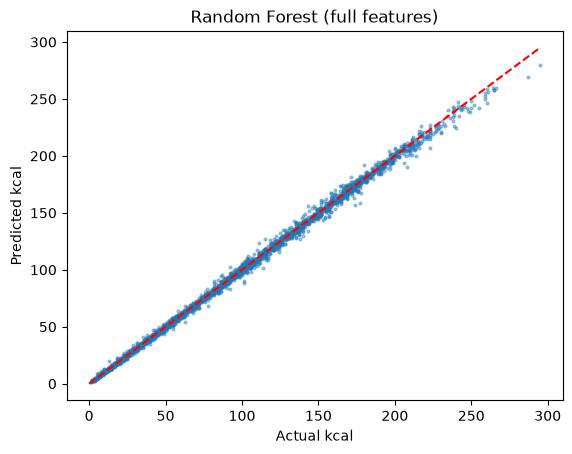

In [12]:
# Predicted vs actual for the best full-feature model
p = fitted[("Random Forest", "full")]
plt.scatter(test[TARGET], p, s=4, alpha=.4); lim = [0, test[TARGET].max()]
plt.plot(lim, lim, "r--"); plt.xlabel("Actual kcal"); plt.ylabel("Predicted kcal")
plt.title("Random Forest (full features)"); plt.show()

In [13]:
# First bias check: error by gender (extend to age groups later)
t = test.copy(); t["abs_err"] = (t[TARGET] - fitted[("Random Forest", "app-only")]).abs()
t.groupby("Gender")["abs_err"].agg(["mean", "count"]).rename(index={0: "female", 1: "male"})

,mean,count
Gender,,
female,7.332219,1510
male,10.436438,1490


**Notes (write your own):**
- How much does each model beat the MET baseline?
- If R² is ~0.99 with full features, what does that say about this dataset?
- How much accuracy is lost without heart rate and body temperature?
- Is the error noticeably different between groups?